# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

## Diabetes Prediction with an Artificial Neural Network

**Learning objective:** develop, train, tune, and evaluate a feed-forward ANN for binary classification. 

- This notebook uses the Pima Indians Diabetes dataset from an online CSV source. 

- It extends the Iris exercise with data-quality checks, feature engineering, class-imbalance analysis, hyperparameter experiments, baseline comparisons, and several evaluation visualizations.

**Prediction task:** predict whether a patient belongs to the diabetes-positive class (`Outcome = 1`) or the diabetes-negative class (`Outcome = 0`) from eight clinical and demographic attributes.

## Notebook roadmap

| Stage | Main activity |
|---|---|
| Data | Load an online CSV, inspect data quality, and understand the target |
| Preparation | Stratified train/validation/test split and missing-value treatment |
| Exploration | Class balance, distributions, outliers, and feature correlations |
| Feature engineering | Add clinically interpretable nonlinear and interaction features |
| ANN | Build a binary classifier with a sigmoid output and binary cross-entropy |
| Model selection | Compare architectures, learning rates, and batch sizes |
| Evaluation | Compare baselines, confusion matrices, precision/recall, ROC and precision-recall curves |
| Interpretation | Permutation importance and inspection of individual predictions |

The test set is reserved for final evaluation. It must not influence preprocessing, feature selection, or hyperparameter selection.

### 1. Import libraries

In [99]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss,
    classification_report, ConfusionMatrixDisplay,
    confusion_matrix, roc_curve, precision_recall_curve,
    balanced_accuracy_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110})
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)

TensorFlow: 2.18.0
Pandas: 2.2.2


### 2. Configure the experiment

In [100]:
RANDOM_STATE = 42
DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

TEST_SIZE = 0.20
VAL_SIZE = 0.20                 # Fraction of the complete dataset
MAX_EPOCHS = 120
PATIENCE = 15
ARTIFACT_DIR = Path("ann_diabetes_artifacts")

TARGET = "Outcome"
CLASS_NAMES = ["No diabetes", "Diabetes"]
tf.keras.utils.set_random_seed(RANDOM_STATE)

### 3. Load the dataset from an online CSV URL
The CSV is read directly into memory. No manual download or local file is required. Internet access is necessary.

In [101]:
raw_df = pd.read_csv(DATA_URL)

print("Source:", DATA_URL)
print("Rows and columns:", raw_df.shape)
display(raw_df.head())

Source: https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv
Rows and columns: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 4. Inspect the dataset and validate its structure

- The dataset contains eight input variables and one binary target. 
- Some physiological measurements use zero as a placeholder for an unrecorded value. In particular, zero is not a plausible value for glucose, blood pressure, skin thickness, insulin, or BMI. 
- We convert those placeholders to missing values before imputation.

We do **not** treat zero pregnancies or zero values in the diabetes pedigree function as missing.

In [102]:
expected_columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", TARGET]
df = raw_df.copy()
df.columns = df.columns.str.strip()

missing_columns = set(expected_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

df = df[expected_columns].copy()
for col in expected_columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df[TARGET].isna().any() or not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("Outcome must contain only binary labels 0 and 1.")

invalid_zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in invalid_zero_columns:
    df.loc[df[col] == 0, col] = np.nan

print("Dataset shape:", df.shape)
df.info()
display(df.isna().sum().rename("Missing values").to_frame())
display(df.describe().T)

Dataset shape: (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


,Missing values
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.8451,3.3696,0.000,1.0000,3.0000,6.0000,17.00
Glucose,763.0,121.6868,30.5356,44.000,99.0000,117.0000,141.0000,199.00
BloodPressure,733.0,72.4052,12.3822,24.000,64.0000,72.0000,80.0000,122.00
SkinThickness,541.0,29.1534,10.4770,7.000,22.0000,29.0000,36.0000,99.00
Insulin,394.0,155.5482,118.7759,14.000,76.2500,125.0000,190.0000,846.00
BMI,757.0,32.4575,6.9250,18.200,27.5000,32.3000,36.6000,67.10
DiabetesPedigreeFunction,768.0,0.4719,0.3313,0.078,0.2437,0.3725,0.6262,2.42
Age,768.0,33.2409,11.7602,21.000,24.0000,29.0000,41.0000,81.00
Outcome,768.0,0.3490,0.4770,0.000,0.0000,0.0000,1.0000,1.00


### 5. Examine the target distribution
- Class imbalance matters. 
- Accuracy alone can be misleading when one class is more common than the other.

,Class,Count,Percentage
0,No diabetes,500,65.1042
1,Diabetes,268,34.8958


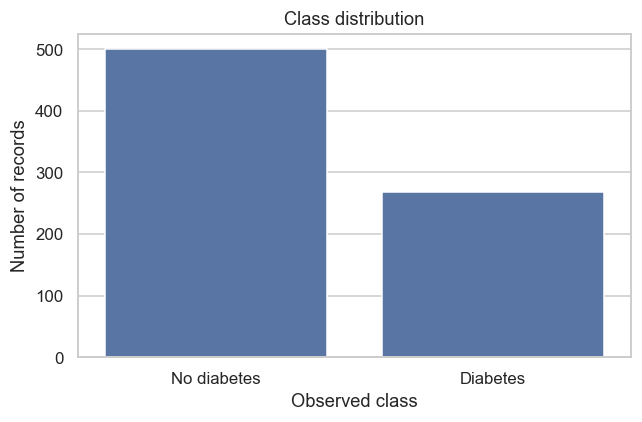

In [103]:
class_counts = df[TARGET].value_counts().sort_index()
class_summary = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Count": [class_counts.get(0, 0), class_counts.get(1, 0)],
    "Percentage": [
        100 * class_counts.get(0, 0) / len(df),
        100 * class_counts.get(1, 0) / len(df)]})
display(class_summary)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set_xticks([0, 1], CLASS_NAMES)
ax.set_xlabel("Observed class")
ax.set_ylabel("Number of records")
ax.set_title("Class distribution")
plt.tight_layout()
plt.show()

### 6. Split the data before preprocessing

We create three mutually exclusive subsets:
- **Training:** 60% of all observations. Used to fit model parameters and preprocessing.
- **Validation:** 20%. Used for model selection and early stopping.
- **Test:** 20%. Used once for the final assessment.

Stratification preserves the approximate class proportions in each subset.

In [104]:
X = df.drop(columns=TARGET).copy()
y = df[TARGET].astype("int32").copy()
base_features = X.columns.tolist()

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=VAL_SIZE / (1 - TEST_SIZE),
    stratify=y_dev, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Rows": [len(y_train), len(y_val), len(y_test)],
    "Share (%)": [
        100 * len(y_train) / len(y),
        100 * len(y_val) / len(y),
        100 * len(y_test) / len(y)],
    "Diabetes positive (%)": [
        100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()]
}, index=["Training", "Validation", "Test"])
display(split_summary)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

,Rows,Share (%),Diabetes positive (%)
Training,460,59.8958,34.7826
Validation,154,20.0521,35.0649
Test,154,20.0521,35.0649


### 7. Explore the training data

- Use the training subset for exploratory decisions that may influence the model. 
- The plots below show the distributions of the original predictors and their relationship with the target.

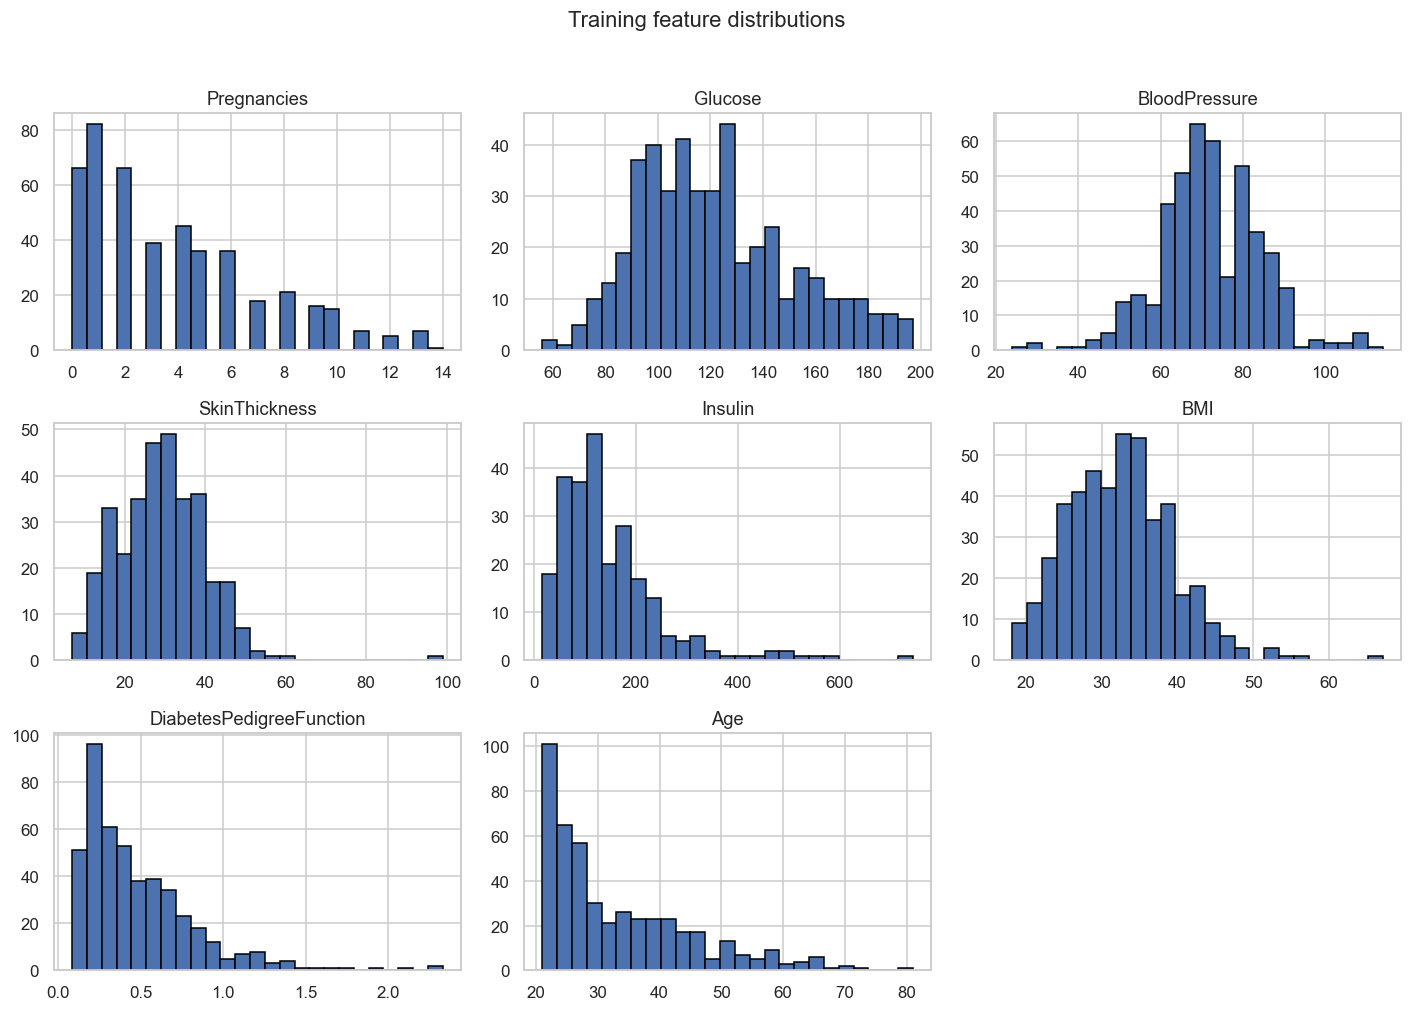

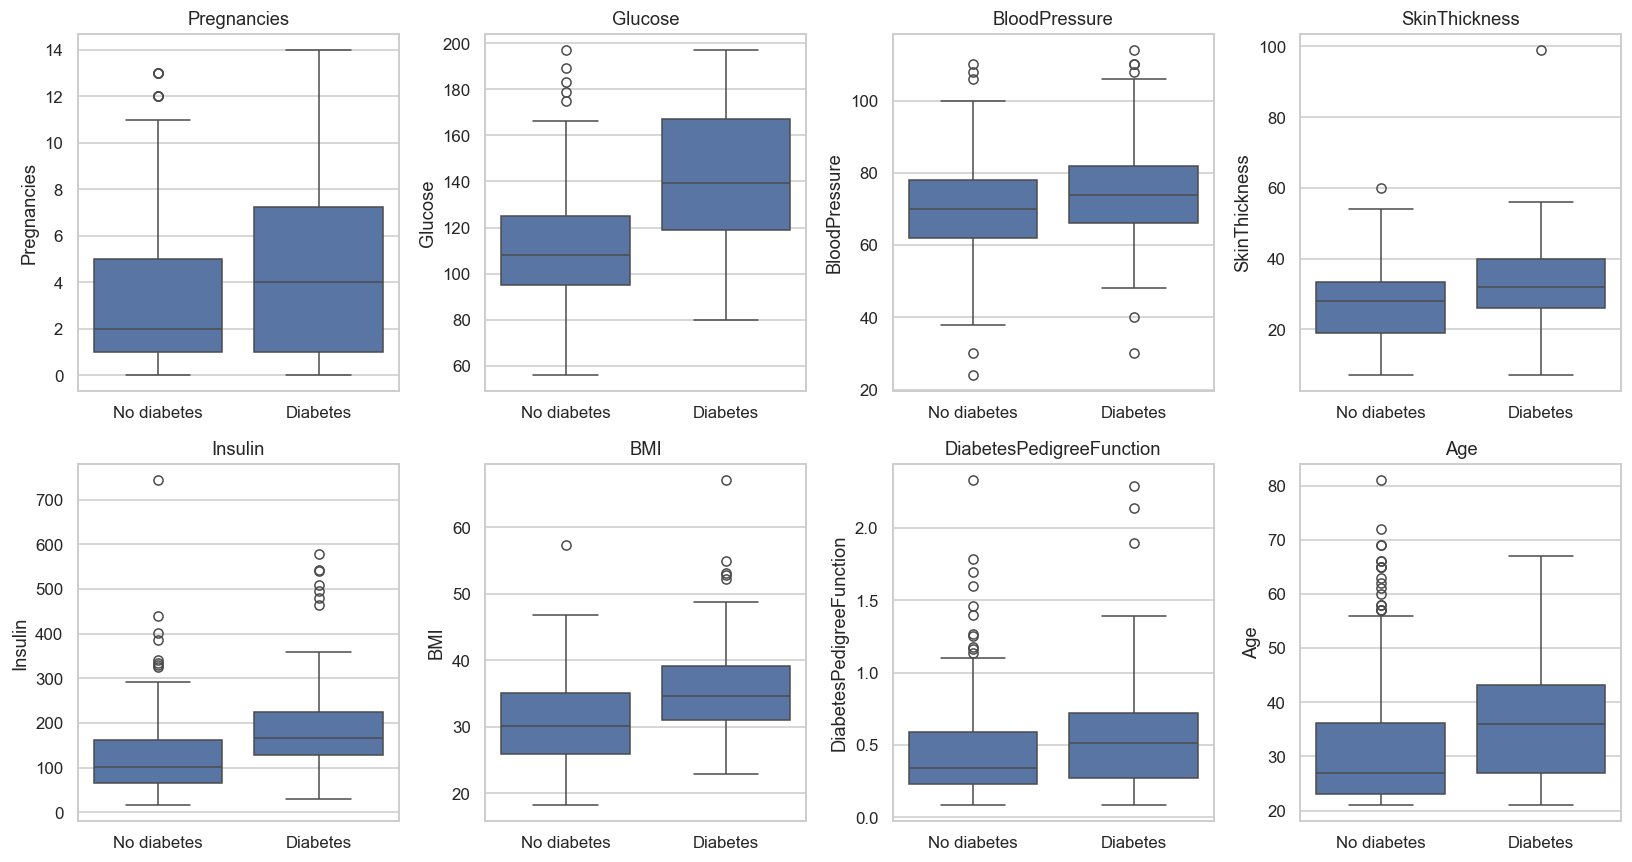

In [105]:
train_explore = X_train.copy()
train_explore[TARGET] = y_train

train_explore[base_features].hist(figsize=(13, 9), bins=25, edgecolor="black")
plt.suptitle("Training feature distributions", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for col, ax in zip(base_features, axes.flat):
    sns.boxplot(data=train_explore, x=TARGET, y=col, ax=ax)
    ax.set_xticks([0, 1], CLASS_NAMES)
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 8. Examine correlations
Correlation is a descriptive measure, not evidence of causality. It also captures only linear association.

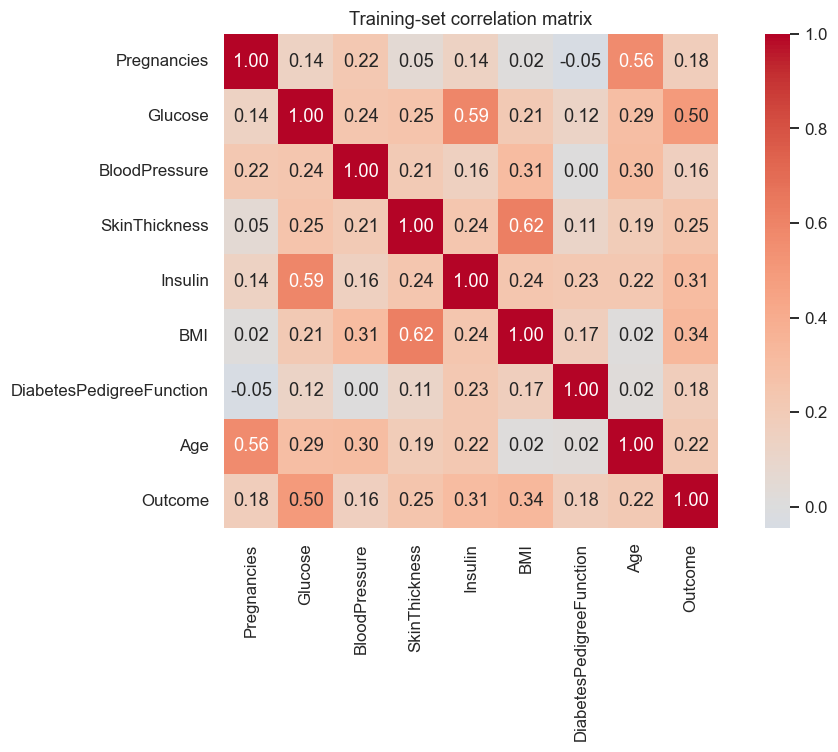

In [106]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(train_explore.corr(numeric_only=True), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Training-set correlation matrix")
plt.tight_layout()
plt.show()

## Feature engineering and preprocessing

### 9. Impute missing values without data leakage

- The imputer is fitted only on the training subset. 
- Its training-set medians are then applied to the validation and test subsets.
- This prevents information from the held-out data from entering preprocessing.

In [108]:
imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=base_features, index=X_train.index)
X_val_imp = pd.DataFrame(imputer.transform(X_val), columns=base_features, index=X_val.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=base_features, index=X_test.index)

print("Missing values after imputation:")
display(X_train_imp.isna().sum().to_frame("Training missing values"))
display(pd.DataFrame({
    "Feature": base_features,
    "Training median used": imputer.statistics_}))

Missing values after imputation:


,Training missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0


,Feature,Training median used
0,Pregnancies,3.000
1,Glucose,117.000
2,BloodPressure,72.000
3,SkinThickness,30.000
4,Insulin,125.000
5,BMI,32.400
6,DiabetesPedigreeFunction,0.389
7,Age,29.000


### 10. Create additional features

We retain the eight original predictors and add three derived variables:

1. `BMI_squared`: a quadratic term that allows the network to represent nonlinear BMI effects more easily.
2. `Age_squared`: a quadratic age term that allows nonlinear age-related patterns.
3. `Glucose_BMI_interaction`: an interaction term that represents a joint glucose and BMI signal.

- These features do not guarantee better performance.
- Their value must be assessed on validation data.
- The test set remains untouched during this process.

In [109]:
def engineer_features(frame):
    engineered = frame.copy()
    engineered["BMI_squared"] = engineered["BMI"] ** 2
    engineered["Age_squared"] = engineered["Age"] ** 2
    engineered["Glucose_BMI_interaction"] = engineered["Glucose"] * engineered["BMI"]
    return engineered

X_train_eng = engineer_features(X_train_imp)
X_val_eng = engineer_features(X_val_imp)
X_test_eng = engineer_features(X_test_imp)
feature_columns = X_train_eng.columns.tolist()

display(X_train_eng.head())
print("Original feature count:", len(base_features))
print("Engineered feature count:", len(feature_columns))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,BMI_squared,Age_squared,Glucose_BMI_interaction
550,1.0,116.0,70.0,28.0,125.0,27.4,0.204,21.0,750.76,441.0,3178.4
749,6.0,162.0,62.0,30.0,125.0,24.3,0.178,50.0,590.49,2500.0,3936.6
69,4.0,146.0,85.0,27.0,100.0,28.9,0.189,27.0,835.21,729.0,4219.4
111,8.0,155.0,62.0,26.0,495.0,34.0,0.543,46.0,1156.00,2116.0,5270.0
573,2.0,98.0,60.0,17.0,120.0,34.7,0.198,22.0,1204.09,484.0,3400.6


Original feature count: 8
Engineered feature count: 11


### 11. Standardize the features

Standardization is important for neural-network optimization. The scaler is fitted on the engineered training features only. Validation and test data use the same training-set means and standard deviations.

In [110]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_eng).astype("float32")
X_val_scaled = scaler.transform(X_val_eng).astype("float32")
X_test_scaled = scaler.transform(X_test_eng).astype("float32")

y_train_array = y_train.to_numpy(dtype="float32")
y_val_array = y_val.to_numpy(dtype="float32")
y_test_array = y_test.to_numpy(dtype="int32")

scaling_summary = pd.DataFrame({
    "Training mean before scaling": scaler.mean_,
    "Training std before scaling": scaler.scale_,
    "Mean after scaling": X_train_scaled.mean(axis=0),
    "Std after scaling": X_train_scaled.std(axis=0)
}, index=feature_columns)
display(scaling_summary)
print("Training input shape:", X_train_scaled.shape)

,Training mean before scaling,Training std before scaling,Mean after scaling,Std after scaling
Pregnancies,3.7761,3.3041,-5.1830e-09,1.0
Glucose,121.8130,29.2285,-1.0366e-08,1.0
BloodPressure,71.8587,12.3094,1.2439e-08,1.0
SkinThickness,29.5957,9.1679,8.2928e-09,1.0
Insulin,137.8522,78.8943,-8.2928e-09,1.0
BMI,32.4652,6.8744,-4.1464e-09,1.0
DiabetesPedigreeFunction,0.4845,0.3410,2.0732e-09,1.0
Age,33.1022,11.7146,2.0732e-09,1.0
BMI_squared,1101.2477,483.0693,0.0000e+00,1.0
Age_squared,1232.9848,952.9379,0.0000e+00,1.0


Training input shape: (460, 11)


## Understanding the ANN

### 12. Binary classification output

The network has one output neuron with a sigmoid activation:

$\hat{p} = \sigma(z) = \frac{1}{1+e^{-z}}$

where, $\hat{p}$ is the estimated probability of the positive class (diabetes), and $z$ is the output neuron's pre-activation value. 

The default decision threshold is 0.5:

$
\hat{y} =
\begin{cases}
1, & \hat{p} \geq 0.5,\\
0, & \hat{p} < 0.5.
\end{cases}
$

### 13. Binary cross-entropy loss

For one observation, binary cross-entropy is

$
\mathcal{L}(y,\hat{p}) =
-\left[y\log(\hat{p})+(1-y)\log(1-\hat{p})\right],
$

where $y\in\{0,1\}$ is the true label and $\hat{p}$ is the predicted probability.

The loss is averaged over the training observations.

### 14. Build a baseline ANN
This first network is a reference architecture. Later, we will compare it with alternative architectures and optimization settings.

In [111]:
def build_ann(input_dim, hidden_units=(32, 16), learning_rate=0.001,
              dropout_rate=0.0, l2_strength=0.0):
    tf.keras.backend.clear_session()
    model = tf.keras.Sequential(name="diabetes_ann")
    model.add(tf.keras.Input(shape=(input_dim,), name="clinical_features"))

    regularizer = (
        tf.keras.regularizers.l2(l2_strength) if l2_strength > 0 else None)
    for layer_index, units in enumerate(hidden_units, start=1):
        model.add(tf.keras.layers.Dense(
            units, activation="relu", kernel_regularizer=regularizer,
            name=f"hidden_{layer_index}"))
        if dropout_rate > 0:
            model.add(tf.keras.layers.Dropout(dropout_rate))

    model.add(tf.keras.layers.Dense(1, activation="sigmoid", name="diabetes_probability"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")])
    return model

baseline_model = build_ann(
    input_dim=X_train_scaled.shape[1],
    hidden_units=(32, 16),
    learning_rate=0.001)
baseline_model.summary()

Model: "diabetes_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ diabetes_probability (Dense)    │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

### 15. Account for class imbalance

Class weights give greater importance to the minority class during training. 

The weights are calculated from the training labels only.

$w_c = \frac{N}{K\,N_c}$

where $N$ is the number of training observations, $K$ is the number of classes, and $N_c$ is the number of training observations in class $c$.

In [112]:
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train_array.astype(int))
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weight)

Class weights: {0: 0.7666666666666667, 1: 1.4375}


### 16. Train the baseline network
Early stopping monitors validation loss and restores the weights from the best epoch.

In [113]:
tf.keras.utils.set_random_seed(RANDOM_STATE)
baseline_model = build_ann(
    input_dim=X_train_scaled.shape[1],
    hidden_units=(32, 16),
    learning_rate=0.001)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
baseline_history = baseline_model.fit(
    X_train_scaled, y_train_array,
    validation_data=(X_val_scaled, y_val_array),
    epochs=MAX_EPOCHS,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stopping],
    verbose=0)
baseline_best_epoch = int(np.argmin(baseline_history.history["val_loss"]) + 1)
print("Epochs executed:", len(baseline_history.history["loss"]))
print("Best validation-loss epoch:", baseline_best_epoch)

Epochs executed: 30
Best validation-loss epoch: 15


### 17. Plot training and validation curves
A widening gap between training and validation loss can indicate overfitting. 

Accuracy should be interpreted together with loss and class-sensitive metrics.

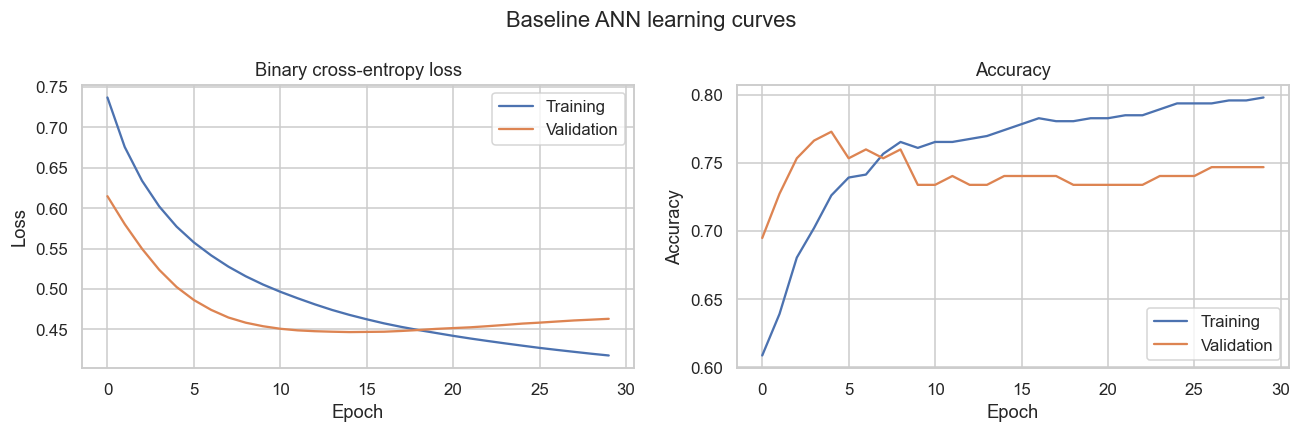

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(baseline_history.history["loss"], label="Training")
axes[0].plot(baseline_history.history["val_loss"], label="Validation")
axes[0].set(title="Binary cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()

axes[1].plot(baseline_history.history["accuracy"], label="Training")
axes[1].plot(baseline_history.history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
fig.suptitle("Baseline ANN learning curves")
plt.tight_layout()
plt.show()

## Hyperparameter experiments

### 18. Define the model-selection protocol

We compare several configurations. The experiment changes hidden-layer widths, learning rate, batch size, and dropout. The same training/validation split and class weights are used for all configurations.

The selected model is the configuration with the highest **positive-class validation F1-score** at the default threshold of 0.5. This choice prioritizes detection of the positive class. ROC-AUC and validation loss are also reported. The test set is not used for selection.

In [115]:
experiments = [
    {"name": "Small / slow", "hidden_units": (16,), "learning_rate": 0.0005,
     "batch_size": 32, "dropout_rate": 0.0},
    {"name": "Baseline", "hidden_units": (32, 16), "learning_rate": 0.001,
     "batch_size": 32, "dropout_rate": 0.0},
    {"name": "Wide / fast", "hidden_units": (64, 32), "learning_rate": 0.003,
     "batch_size": 32, "dropout_rate": 0.0},
    {"name": "Regularized", "hidden_units": (64, 32), "learning_rate": 0.001,
     "batch_size": 16, "dropout_rate": 0.25},
    {"name": "Deeper", "hidden_units": (64, 32, 16), "learning_rate": 0.001,
     "batch_size": 32, "dropout_rate": 0.15},]

### 19. Run the hyperparameter experiments
Each configuration is trained independently. Early stopping limits unnecessary epochs.

In [82]:
experiment_results = []
trained_models = {}
trained_histories = {}

for i, config in enumerate(experiments):
    print(f"Training {i+1}/{len(experiments)}: {config['name']}")
    tf.keras.utils.set_random_seed(RANDOM_STATE + i)

    candidate = build_ann(
        input_dim=X_train_scaled.shape[1],
        hidden_units=config["hidden_units"],
        learning_rate=config["learning_rate"],
        dropout_rate=config["dropout_rate"])
    callback = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    history = candidate.fit(
        X_train_scaled, y_train_array,
        validation_data=(X_val_scaled, y_val_array),
        epochs=MAX_EPOCHS,
        batch_size=config["batch_size"],
        class_weight=class_weight,
        callbacks=[callback],
        verbose=0)

    val_prob = candidate.predict(X_val_scaled, verbose=0).ravel()
    val_pred = (val_prob >= 0.5).astype(int)

    experiment_results.append({
        "name": config["name"],
        "hidden_units": str(config["hidden_units"]),
        "learning_rate": config["learning_rate"],
        "batch_size": config["batch_size"],
        "dropout": config["dropout_rate"],
        "epochs": len(history.history["loss"]),
        "best_val_loss": float(np.min(history.history["val_loss"])),
        "val_accuracy": accuracy_score(y_val_array, val_pred),
        "val_precision": precision_score(y_val_array, val_pred, zero_division=0),
        "val_recall": recall_score(y_val_array, val_pred, zero_division=0),
        "val_f1": f1_score(y_val_array, val_pred, zero_division=0),
        "val_roc_auc": roc_auc_score(y_val_array, val_prob)})
    trained_models[config["name"]] = candidate
    trained_histories[config["name"]] = history

results_df = pd.DataFrame(experiment_results).sort_values(
    ["val_f1", "val_roc_auc", "best_val_loss"],
    ascending=[False, False, True]
).reset_index(drop=True)
display(results_df)

Training 1/5: Small / slow
Training 2/5: Baseline
Training 3/5: Wide / fast
Training 4/5: Regularized
Training 5/5: Deeper


,name,hidden_units,learning_rate,batch_size,dropout,epochs,best_val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
0,Wide / fast,"(64, 32)",0.0030,32,0.00,18,0.4516,0.7857,0.6567,0.8148,0.7273,0.8665
1,Small / slow,"(16,)",0.0005,32,0.00,120,0.4497,0.7857,0.6615,0.7963,0.7227,0.8702
2,Baseline,"(32, 16)",0.0010,32,0.00,32,0.4664,0.7532,0.6250,0.7407,0.6780,0.8493
3,Regularized,"(64, 32)",0.0010,16,0.25,34,0.4427,0.7597,0.6441,0.7037,0.6726,0.8674
4,Deeper,"(64, 32, 16)",0.0010,32,0.15,23,0.4432,0.7662,0.6731,0.6481,0.6604,0.8676


### 20. Visualize the hyperparameter comparison
These plots help reveal trade-offs. They do not establish that one hyperparameter is universally optimal.

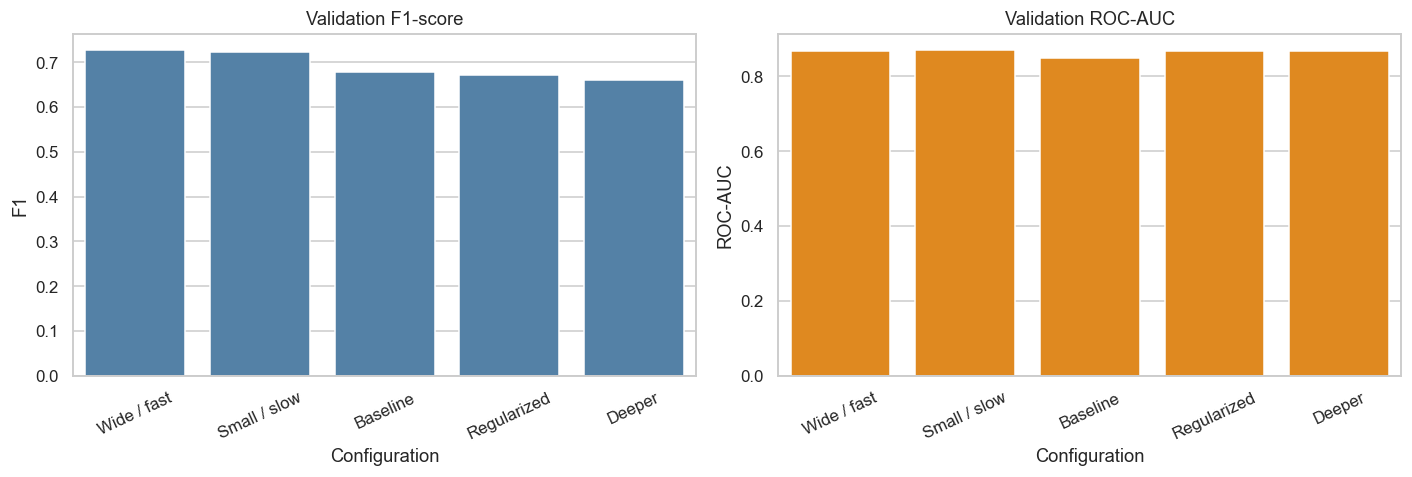

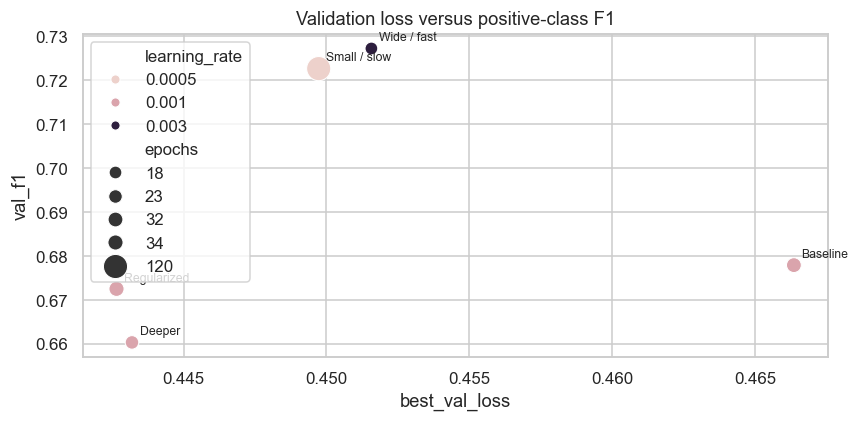

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=results_df, x="name", y="val_f1", color="steelblue", ax=axes[0])
axes[0].set(title="Validation F1-score", xlabel="Configuration", ylabel="F1")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(data=results_df, x="name", y="val_roc_auc", color="darkorange", ax=axes[1])
axes[1].set(title="Validation ROC-AUC", xlabel="Configuration", ylabel="ROC-AUC")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(
    data=results_df, x="best_val_loss", y="val_f1",
    size="epochs", hue="learning_rate", sizes=(70, 250), ax=ax)
for _, row in results_df.iterrows():
    ax.annotate(row["name"], (row["best_val_loss"], row["val_f1"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_title("Validation loss versus positive-class F1")
plt.tight_layout()
plt.show()

### 21. Select the best validation configuration

In [117]:
best_name = results_df.loc[0, "name"]
best_model = trained_models[best_name]
best_config = next(item for item in experiments if item["name"] == best_name)
best_history = trained_histories[best_name]

print("Selected configuration:", best_name)
print("Configuration:", best_config)
print("Validation F1:", results_df.loc[0, "val_f1"])
print("Validation ROC-AUC:", results_df.loc[0, "val_roc_auc"])

Selected configuration: Wide / fast
Configuration: {'name': 'Wide / fast', 'hidden_units': (64, 32), 'learning_rate': 0.003, 'batch_size': 32, 'dropout_rate': 0.0}
Validation F1: 0.7272727272727273
Validation ROC-AUC: 0.8664814814814814


### 22. Inspect the selected model's learning curves

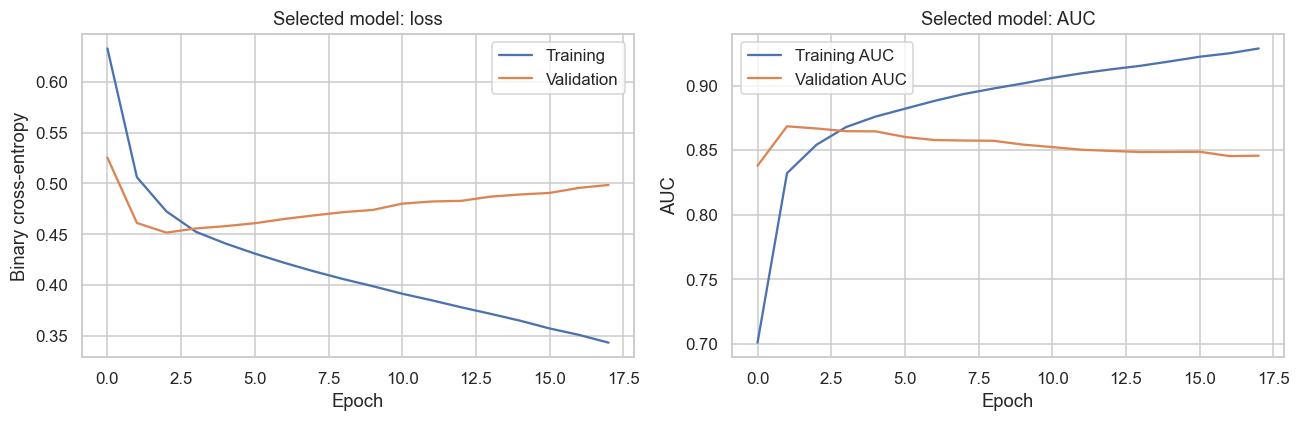

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_history.history["loss"], label="Training")
axes[0].plot(best_history.history["val_loss"], label="Validation")
axes[0].set(title="Selected model: loss", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[0].legend()

axes[1].plot(best_history.history["auc"], label="Training AUC")
axes[1].plot(best_history.history["val_auc"], label="Validation AUC")
axes[1].set(title="Selected model: AUC", xlabel="Epoch", ylabel="AUC")
axes[1].legend()
plt.tight_layout()
plt.show()

## Baselines and final test evaluation

### 23. Train conventional baselines

A majority-class dummy classifier provides a minimal reference. Logistic regression provides a linear decision-boundary baseline. The logistic-regression pipeline fits its own imputer and scaler on the training subset only.

In [119]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))])
logistic_model.fit(X_train, y_train)

print("Dummy and logistic-regression baselines are trained.")

Dummy and logistic-regression baselines are trained.


### 24. Evaluate all models on the held-out test set
The test set is used only after model selection. The ANN uses the feature engineering and preprocessing fitted on the training data.

In [120]:
ann_test_prob = best_model.predict(X_test_scaled, verbose=0).ravel()
ann_test_pred = (ann_test_prob >= 0.5).astype(int)

logistic_test_prob = logistic_model.predict_proba(X_test)[:, 1]
logistic_test_pred = (logistic_test_prob >= 0.5).astype(int)

dummy_test_pred = dummy_model.predict(X_test)

def calculate_metrics(y_true, y_pred, y_prob=None):
    values = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)}
    if y_prob is not None:
        values["ROC-AUC"] = roc_auc_score(y_true, y_prob)
        values["PR-AUC (Average Precision)"] = average_precision_score(y_true, y_prob)
        values["Log loss"] = log_loss(y_true, y_prob)
    return values

test_comparison = pd.DataFrame({
    "Dummy": calculate_metrics(y_test_array, dummy_test_pred),
    "Logistic regression": calculate_metrics(
        y_test_array, logistic_test_pred, logistic_test_prob
    ),
    "ANN": calculate_metrics(y_test_array, ann_test_pred, ann_test_prob)
}).T
display(test_comparison.round(4))

,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC (Average Precision),Log loss
Dummy,0.6494,0.5000,0.0000,0.0000,0.0000,NaN,NaN,NaN
Logistic regression,0.7273,0.7176,0.5968,0.6852,0.6379,0.8156,0.6805,0.5393
ANN,0.7273,0.7219,0.5938,0.7037,0.6441,0.8022,0.6553,0.5453


### 25. Confusion matrix

For binary classification:

| | Predicted negative | Predicted positive |
|---|---:|---:|
| **Actual negative** | True Negative (TN) | False Positive (FP) |
| **Actual positive** | False Negative (FN) | True Positive (TP) |

The confusion matrix makes the types of classification error explicit. A false negative means that a diabetes-positive observation was classified as negative. A false positive means that a diabetes-negative observation was classified as positive.

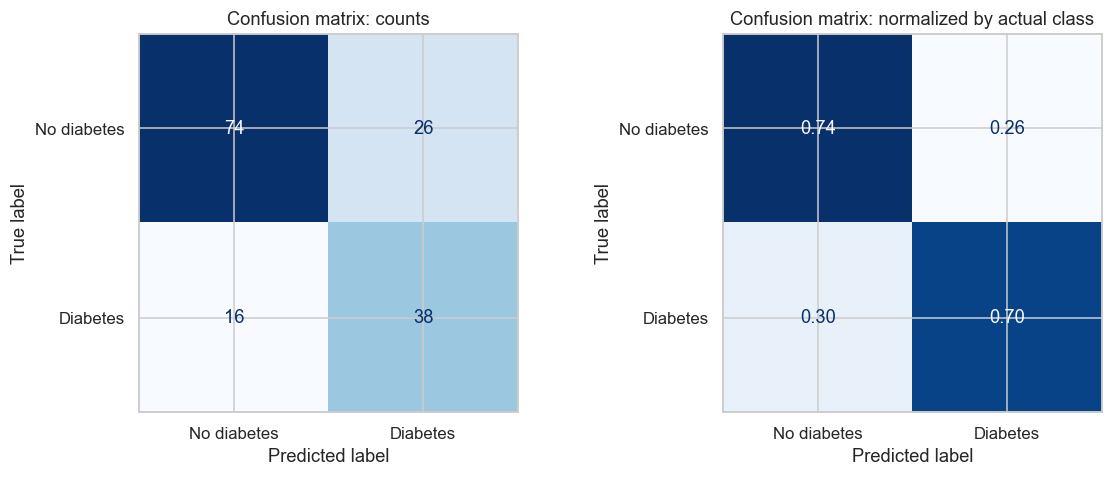

TN=74, FP=26, FN=16, TP=38


In [121]:
cm = confusion_matrix(y_test_array, ann_test_pred, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    cmap="Blues", colorbar=False, ax=axes[0], values_format="d")
axes[0].set_title("Confusion matrix: counts")

cm_normalized = confusion_matrix(
    y_test_array, ann_test_pred, labels=[0, 1], normalize="true")
ConfusionMatrixDisplay(cm_normalized, display_labels=CLASS_NAMES).plot(
    cmap="Blues", colorbar=False, ax=axes[1], values_format=".2f")
axes[1].set_title("Confusion matrix: normalized by actual class")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

### 26. Precision, recall, F1-score, and support

Treat diabetes as the positive class.

$
\mathrm{Precision} = \frac{TP}{TP+FP}
\qquad
\mathrm{Recall} = \frac{TP}{TP+FN}
$

$
F_1 = 2\frac{\mathrm{Precision}\times\mathrm{Recall}}
{\mathrm{Precision}+\mathrm{Recall}}
= \frac{2TP}{2TP+FP+FN}
$

$
\mathrm{Specificity} = \frac{TN}{TN+FP}
\qquad
\mathrm{Support}_{+}=TP+FN
$

Precision answers: among the observations predicted as positive, what fraction is truly positive? Recall answers: among all truly positive observations, what fraction did the model detect? Support is the number of actual observations in a class.

In [122]:
print(classification_report(
    y_test_array, ann_test_pred,
    labels=[0, 1], target_names=CLASS_NAMES, zero_division=0))

specificity = tn / (tn + fp) if (tn + fp) else 0.0
print(f"Specificity: {specificity:.4f}")

              precision    recall  f1-score   support

 No diabetes       0.82      0.74      0.78       100
    Diabetes       0.59      0.70      0.64        54

    accuracy                           0.73       154
   macro avg       0.71      0.72      0.71       154
weighted avg       0.74      0.73      0.73       154

Specificity: 0.7400


### 27. ROC curve and precision-recall curve
ROC-AUC measures ranking quality across thresholds. 

The precision-recall curve is particularly informative when the positive class is less frequent.

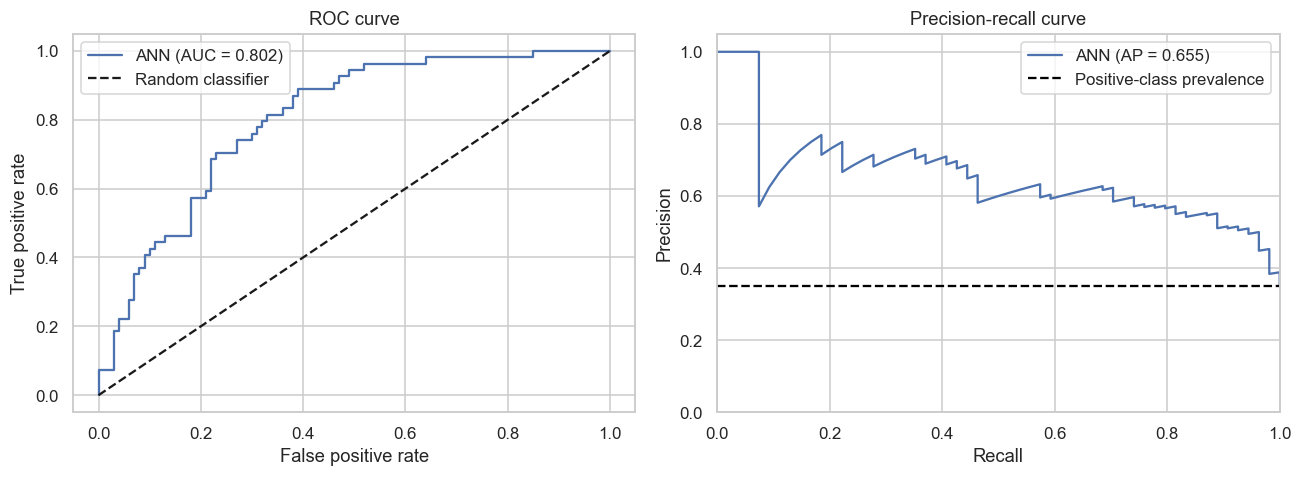

In [123]:
fpr, tpr, roc_thresholds = roc_curve(y_test_array, ann_test_prob)
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test_array, ann_test_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f"ANN (AUC = {roc_auc_score(y_test_array, ann_test_prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random classifier")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate",
            title="ROC curve")
axes[0].legend()

axes[1].plot(recall_values, precision_values,
             label=f"ANN (AP = {average_precision_score(y_test_array, ann_test_prob):.3f})")
axes[1].axhline(y_test_array.mean(), linestyle="--", color="black",
                label="Positive-class prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision",
            title="Precision-recall curve", xlim=(0, 1), ylim=(0, 1.05))
axes[1].legend()
plt.tight_layout()
plt.show()

### 28. Study the effect of the decision threshold

The default threshold of 0.5 is not necessarily optimal. 

A lower threshold usually increases recall and may reduce precision. 

Threshold selection must be based on validation data and the costs of false positives and false negatives. 

The code below illustrates the trade-off on the validation set. 

It does not use test labels to select a threshold.

,Threshold,Precision,Recall,F1
0,0.20,0.530,0.981,0.688
1,0.25,0.543,0.944,0.689
2,0.30,0.543,0.926,0.685
3,0.35,0.565,0.889,0.691
4,0.40,0.590,0.852,0.697
5,0.45,0.600,0.833,0.698
6,0.50,0.657,0.815,0.727
7,0.55,0.700,0.778,0.737
8,0.60,0.685,0.685,0.685
9,0.65,0.714,0.556,0.625


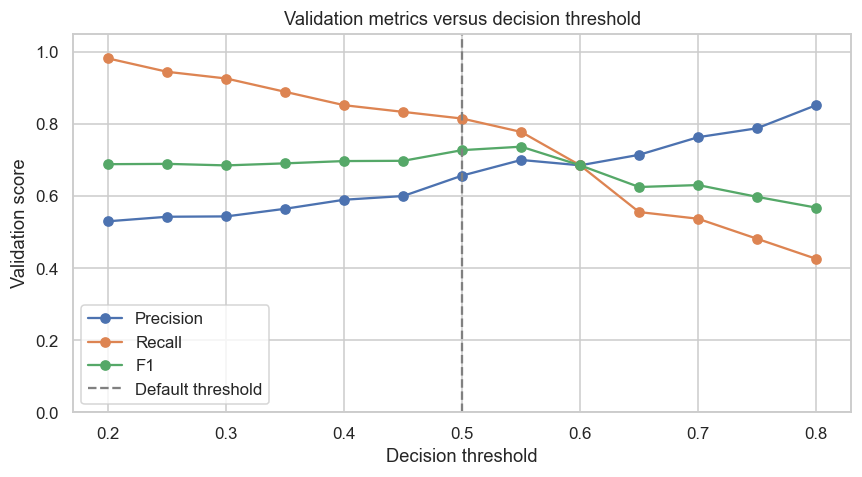

In [124]:
val_prob_selected = best_model.predict(X_val_scaled, verbose=0).ravel()
thresholds = np.arange(0.20, 0.81, 0.05)

threshold_rows = []
for threshold in thresholds:
    val_pred_threshold = (val_prob_selected >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_array, val_pred_threshold, zero_division=0),
        "Recall": recall_score(y_val_array, val_pred_threshold, zero_division=0),
        "F1": f1_score(y_val_array, val_pred_threshold, zero_division=0)})
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for metric in ["Precision", "Recall", "F1"]:
    ax.plot(threshold_df["Threshold"], threshold_df[metric], marker="o", label=metric)
ax.axvline(0.5, linestyle="--", color="gray", label="Default threshold")
ax.set(xlabel="Decision threshold", ylabel="Validation score",
       title="Validation metrics versus decision threshold", ylim=(0, 1.05))
ax.legend()
plt.tight_layout()
plt.show()

### 29. Optional: apply a validation-selected threshold to the test set

For illustration, choose the threshold that maximizes validation F1. 

In a real application, the operating point should reflect the relative costs of false negatives and false positives. 

The threshold is selected without using the test labels.

Validation-selected threshold: 0.5499999999999999
Test metrics at threshold 0.5:


Accuracy                      0.7273
Balanced accuracy             0.7219
Precision                     0.5938
Recall                        0.7037
F1-score                      0.6441
ROC-AUC                       0.8022
PR-AUC (Average Precision)    0.6553
Log loss                      0.5453
dtype: float64

Test metrics at validation-selected threshold:


Accuracy                      0.7273
Balanced accuracy             0.7048
Precision                     0.6071
Recall                        0.6296
F1-score                      0.6182
ROC-AUC                       0.8022
PR-AUC (Average Precision)    0.6553
Log loss                      0.5453
dtype: float64

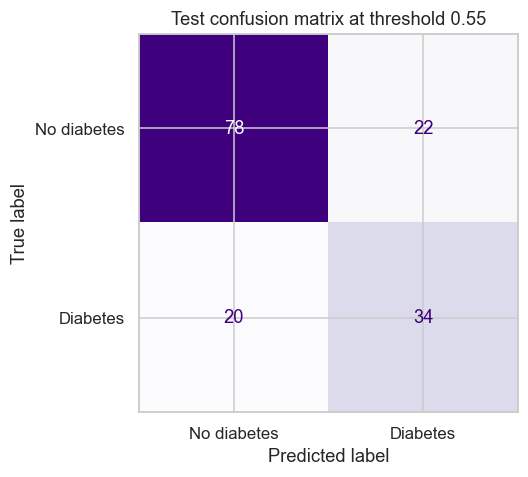

In [125]:
best_threshold = float(
    threshold_df.loc[threshold_df["F1"].idxmax(), "Threshold"])
test_pred_tuned = (ann_test_prob >= best_threshold).astype(int)

print("Validation-selected threshold:", best_threshold)
print("Test metrics at threshold 0.5:")
display(pd.Series(calculate_metrics(y_test_array, ann_test_pred, ann_test_prob)))
print("Test metrics at validation-selected threshold:")
display(pd.Series(calculate_metrics(y_test_array, test_pred_tuned, ann_test_prob)))

ConfusionMatrixDisplay.from_predictions(
    y_test_array, test_pred_tuned, display_labels=CLASS_NAMES,
    cmap="Purples", colorbar=False)
plt.title(f"Test confusion matrix at threshold {best_threshold:.2f}")
plt.tight_layout()
plt.show()

## Model interpretation and error analysis

### 30. Permutation feature importance

Permutation importance measures the reduction in a chosen score after one feature is randomly shuffled. 

A larger reduction indicates greater reliance on that feature for the selected evaluation metric. 

Correlated predictors can share or mask importance. The result is predictive, not causal.

We compute importance on the held-out test set for demonstration. 

In a strict model-development workflow, interpretation that informs further model changes should use validation data instead.

,Feature,Mean F1 decrease,Std
1,Glucose,0.0601,0.0310
6,DiabetesPedigreeFunction,0.0257,0.0203
0,Pregnancies,0.0257,0.0191
10,Glucose_BMI_interaction,0.0119,0.0390
9,Age_squared,0.0050,0.0122
3,SkinThickness,-0.0035,0.0117
4,Insulin,-0.0057,0.0062
7,Age,-0.0099,0.0139
2,BloodPressure,-0.0109,0.0153
8,BMI_squared,-0.0110,0.0183


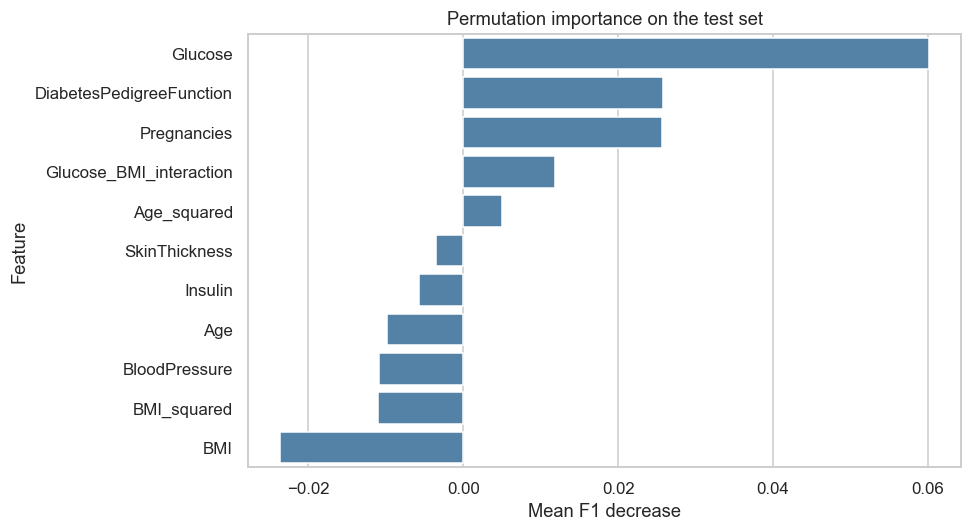

In [126]:
def ann_positive_f1(estimator, X_array, y_true):
    probabilities = estimator.predict(X_array, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    return f1_score(y_true, predictions, zero_division=0)

rng = np.random.default_rng(RANDOM_STATE)
permutation_scores = []
baseline_f1 = ann_positive_f1(best_model, X_test_scaled, y_test_array)

for j, feature in enumerate(feature_columns):
    score_drops = []
    for repeat in range(10):
        permuted = X_test_scaled.copy()
        permuted[:, j] = rng.permutation(permuted[:, j])
        permuted_f1 = ann_positive_f1(best_model, permuted, y_test_array)
        score_drops.append(baseline_f1 - permuted_f1)
    permutation_scores.append({
        "Feature": feature,
        "Mean F1 decrease": np.mean(score_drops),
        "Std": np.std(score_drops)})

importance_df = pd.DataFrame(permutation_scores).sort_values(
    "Mean F1 decrease", ascending=False)
display(importance_df)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=importance_df, x="Mean F1 decrease", y="Feature",
            color="steelblue", ax=ax)
ax.set_title("Permutation importance on the test set")
plt.tight_layout()
plt.show()

### 31. Inspect individual predictions
Review both confident correct predictions and confident errors. 

A probability is a model score, not a calibrated clinical risk unless calibration has been evaluated.

In [127]:
prediction_review = X_test.copy()
prediction_review["Actual"] = y_test_array
prediction_review["Predicted"] = ann_test_pred
prediction_review["Predicted probability (diabetes)"] = ann_test_prob
prediction_review["Correct"] = prediction_review["Actual"] == prediction_review["Predicted"]
prediction_review["Confidence"] = np.maximum(ann_test_prob, 1 - ann_test_prob)

display(prediction_review.sort_values(
    ["Correct", "Confidence"], ascending=[True, False]
).head(12))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Actual,Predicted,Predicted probability (diabetes),Correct,Confidence
6,3,78.0,50.0,32.0,88.0,31.0,0.248,26,1,0,0.0486,False,0.9514
335,0,165.0,76.0,43.0,255.0,47.9,0.259,26,0,1,0.9382,False,0.9382
247,0,165.0,90.0,33.0,680.0,52.3,0.427,23,0,1,0.9340,False,0.9340
469,6,154.0,78.0,41.0,140.0,46.1,0.571,27,0,1,0.9336,False,0.9336
260,3,191.0,68.0,15.0,130.0,30.9,0.299,34,0,1,0.8849,False,0.8849
276,7,106.0,60.0,24.0,NaN,26.5,0.296,29,1,0,0.1229,False,0.8771
212,7,179.0,95.0,31.0,NaN,34.2,0.164,60,0,1,0.8700,False,0.8700
436,12,140.0,85.0,33.0,NaN,37.4,0.244,41,0,1,0.8542,False,0.8542
153,1,153.0,82.0,42.0,485.0,40.6,0.687,23,0,1,0.8381,False,0.8381
124,0,113.0,76.0,NaN,NaN,33.3,0.278,23,1,0,0.1887,False,0.8113


## Save and reproduce the model

### 32. Save the model and preprocessing objects

The ANN, imputer, scaler, feature definitions, and selected hyperparameters are saved separately. 

These components form one inference pipeline. 

A saved neural network without its preprocessing objects is not sufficient for reproducible predictions.

In [128]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
best_model.save(ARTIFACT_DIR / "diabetes_ann.keras")

import joblib
joblib.dump(imputer, ARTIFACT_DIR / "median_imputer.joblib")
joblib.dump(scaler, ARTIFACT_DIR / "standard_scaler.joblib")

metadata = {
    "data_url": DATA_URL,
    "target": TARGET,
    "class_names": CLASS_NAMES,
    "base_features": base_features,
    "engineered_features": feature_columns,
    "selected_configuration": best_config,
    "decision_threshold_default": 0.5,
    "validation_selected_threshold": best_threshold,
    "random_state": RANDOM_STATE,
    "tensorflow_version": tf.__version__}
(ARTIFACT_DIR / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved artifacts to:", ARTIFACT_DIR.resolve())

Saved artifacts to: C:\Users\user\Documents\GitHub\AI\ann_diabetes_artifacts


### 33. Reload and verify inference
The same imputation, feature-engineering, and scaling steps must be applied to new observations in the same order.

In [129]:
loaded_model = tf.keras.models.load_model(ARTIFACT_DIR / "diabetes_ann.keras")
loaded_imputer = joblib.load(ARTIFACT_DIR / "median_imputer.joblib")
loaded_scaler = joblib.load(ARTIFACT_DIR / "standard_scaler.joblib")

sample_raw = X_test.iloc[[0]].copy()
sample_imputed = pd.DataFrame(
    loaded_imputer.transform(sample_raw),
    columns=base_features,
    index=sample_raw.index)
sample_engineered = engineer_features(sample_imputed)
sample_scaled = loaded_scaler.transform(sample_engineered).astype("float32")

original_probability = float(best_model.predict(sample_scaled, verbose=0)[0, 0])
reloaded_probability = float(loaded_model.predict(sample_scaled, verbose=0)[0, 0])

print("Original model probability:", original_probability)
print("Reloaded model probability:", reloaded_probability)
assert np.isclose(original_probability, reloaded_probability, atol=1e-6)
print("Verification passed.")

Original model probability: 0.7335969805717468
Reloaded model probability: 0.7335969805717468
Verification passed.


### Final reminder

- A more complex ANN does not automatically provide better generalization. For a small tabular dataset, a carefully validated logistic-regression model can be competitive. 
- Report the held-out test results, class-sensitive metrics, and limitations rather than selecting a model based on training accuracy alone.